# Exercises week 37

**FYS-STK3155/4155, fall 2026 — deadline Friday September 11 at midnight.**

## Implementing gradient descent for ordinary least squares and Ridge regression

The aim this week is that you write, and *check*, your own gradient descent
code for OLS and Ridge regression, and that you understand what the learning
rate can and cannot be. Everything here is reused directly in part e) of
Project 1, and exercise 6 opens part f). The code developed in the Tuesday
session (`week37tuesday.ipynb`, Case 1) is meant to be reused.

After completing these exercises you will have

* your own code for the simplest gradient descent approach applied to
  ordinary least squares (OLS) and Ridge regression, with a stopping criterion;
* compared the analytical expressions for the OLS and Ridge parameters with
  the gradient descent results;
* explored the role of the learning rate $\gamma$ in gradient descent and of the
  hyperparameter $\lambda$ in Ridge regression, and related the largest usable
  learning rate to the largest eigenvalue of the Hessian (Section 4.5 of the
  lecture notes);
* checked your analytical gradient against automatic differentiation
  (Section 4.14) and added momentum (Section 4.6);
* scaled the data properly.

Reading: Chapter 4, Sections 4.1–4.6 and 4.14 of the book; Goodfellow et al.,
Chapter 4 and Sections 8.1–8.3.

## A simple one-dimensional second-order polynomial

We start with a very simple function,

$$
f(x) = 2 - x + 5x^2,
$$

defined for $x \in [-2, 2]$. You can add noise if you wish (the Tuesday
session used Gaussian noise with standard deviation $0.5$). We fit this
function with a polynomial ansatz. The easiest thing is to set up a
second-order polynomial and see if you can recover the above function; feel
free to play around with higher-order polynomials — the Tuesday session shows
that a degree-5 fit of the same data is a much harder problem for gradient
descent, and exercise 4 asks you why.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
n = 100
x = rng.uniform(-2.0, 2.0, n)
y = 2.0 - x + 5.0 * x**2 + 0.5 * rng.standard_normal(n)   # drop the noise term if you prefer

BLUE, RED, YELLOW, GREY = "#004488", "#BB5566", "#DDAA33", "#777777"

## Exercise 1: scale your data

Before fitting a regression model it is good practice to standardise the
features. This ensures all features are on a comparable scale, which is
especially important when using regularisation — and, as Section 4.5 of the
lecture notes shows, it is also what makes gradient descent converge in a
reasonable number of iterations. Here we standardise, scaling each feature to
have mean $0$ and standard deviation $1$.

### 1a)

Set up the design matrix $\boldsymbol{X}$ with the columns $x$ and $x^2$ (no
column of ones). Compute the mean and standard deviation of each column,
subtract the mean and divide by the standard deviation.

We also centre the target $\boldsymbol{y}$ to mean $0$. Centring
$\boldsymbol{y}$ and each feature means the model does not need a separate
intercept term: the data are shifted so that the intercept is effectively
$0$. (In practice one can include an intercept in the model and leave it
unpenalised, see Section 3.13 of the lecture notes; here we simplify by
centring.)

In [2]:
X = np.column_stack([x, x**2])

# Standardize features (zero mean, unit variance for each feature)
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_std[X_std == 0] = 1  # safeguard to avoid division by zero for constant features
X_norm = (X - X_mean) / X_std

# Center the target to zero mean (optional, to simplify intercept handling)
y_mean = y.mean()
y_centered = y - y_mean

print("Answer: If we do not centre the values, we will have an intercept, which can be problematic for Ridge as the penalising will affect this considerably. For OLS, this is not a problem as we do not penalise. Scaling is also important to make sure all features are on the same scale and therefore not weighted differently. This can for example be a problem if we include different variables with different units, such as precipitation, temperature, etc.")


""" Functions from tuesday week 37 cases """
def exercise_data(degree=2):

    rng = np.random.default_rng(2026)
    n = 100
    x = rng.uniform(-2.0, 2.0, n)
    y = 2.0 - x + 5.0 * x**2 + 0.5 * rng.standard_normal(n)   # drop the noise term if you prefer

    #X = np.column_stack([x, x**2])
    X = np.column_stack([x**k for k in range(1, degree + 1)])

    # Standardize features (zero mean, unit variance for each feature)
    X_mean = X.mean(axis=0)
    X_std = X.std(axis=0)
    X_std[X_std == 0] = 1  # safeguard to avoid division by zero for constant features
    X_norm = (X - X_mean) / X_std

    # Center the target to zero mean (optional, to simplify intercept handling)
    y_mean = y.mean()
    y_centered = y - y_mean

    return X_norm, y_centered


Answer: If we do not centre the values, we will have an intercept, which can be problematic for Ridge as the penalising will affect this considerably. For OLS, this is not a problem as we do not penalise. Scaling is also important to make sure all features are on the same scale and therefore not weighted differently. This can for example be a problem if we include different variables with different units, such as precipitation, temperature, etc.


Fill in the necessary details. Do we need to centre the $y$-values? What
would go wrong, for OLS and for Ridge, if we did not?


After this preprocessing each column of $\boldsymbol{X}_{\mathrm{norm}}$ has
mean zero and standard deviation $1$ and $\boldsymbol{y}_{\mathrm{centered}}$
has mean $0$. This makes the optimisation landscape nicer and ensures that the
penalty $\lambda\sum_j\theta_j^2$ in Ridge regression treats each coefficient
fairly, since the features are on the same scale.

### 1b)

The true function has coefficients $(-1, 5)$ on $(x, x^2)$. Which
coefficients do you expect to find on the *standardised* columns, and how do
you convert the fitted parameters back to the original scale?


#### Answer:
I would expect to find coefficients close to the true coefficients, but not the exact values, as the columns are standardised and therefore will change the values. To convert the fitted parameters back to original scale, we can skip the standardisation.


## Exercise 2: calculate the gradients and the Hessian

Find the gradients of the OLS and Ridge cost functions,

$$
C_{\mathrm{OLS}}(\boldsymbol{\theta}) = \frac{1}{n}\|\boldsymbol{X}\boldsymbol{\theta} - \boldsymbol{y}\|_2^2,
\qquad
C_{\mathrm{Ridge}}(\boldsymbol{\theta}) = \frac{1}{n}\|\boldsymbol{X}\boldsymbol{\theta} - \boldsymbol{y}\|_2^2 + \lambda\boldsymbol{\theta}^T\boldsymbol{\theta},
$$

with respect to $\boldsymbol{\theta}$ (Eqs. (4.13) and (4.17) of the lecture
notes). Find also the Hessian matrices, and show that the OLS Hessian is
positive semi-definite and the Ridge Hessian positive definite for
$\lambda > 0$ — that is, that both cost functions are convex (Section 4.1).
Why does this matter for gradient descent?

Setting the Ridge gradient to zero, show that the minimiser is
$\hat{\boldsymbol{\theta}} = (\boldsymbol{X}^T\boldsymbol{X} + n\lambda\boldsymbol{I})^{-1}\boldsymbol{X}^T\boldsymbol{y}$.
Where does the factor $n$ come from, and what is the corresponding `alpha`
of `scikit-learn`'s `Ridge`? (Section 3.10 and Eq. (3.95).)



## Exercise 3: the analytical formulae for OLS and Ridge regression

In [3]:
# Set regularization parameter, either a single value or a vector of values
# Note that lambda is a python keyword: the lambda keyword creates small anonymous functions.
lam = 0.01
X_norm, y = exercise_data(degree=2)
#3a:
# Analytical forms: theta_Ridge = (X^T X + n*lambda*I)^{-1} X^T y and theta_OLS = (X^T X)^{-1} X^T y
n_features = X_norm.shape[1]
I = np.eye(n_features)
theta_closed_formRidge = np.linalg.solve(X_norm.T @ X_norm + n * lam * I, X_norm.T @ y)
theta_closed_formOLS = np.linalg.solve(X_norm.T @ X_norm, X_norm.T @ y)

print("Closed-form Ridge coefficients:", theta_closed_formRidge)
print("Closed-form OLS coefficients:", theta_closed_formOLS)


#3b:

#Looping through different lambdas
for lam in [0.0, 0.01, 0.1, 1.0]:
    # Analytical forms: theta_Ridge = (X^T X + n*lambda*I)^{-1} X^T y and theta_OLS = (X^T X)^{-1} X^T y
    n_features = X_norm.shape[1]
    I = np.eye(n_features)
    theta_closed_formRidge = np.linalg.solve(X_norm.T @ X_norm + n * lam * I, X_norm.T @ y)
    theta_closed_formOLS = np.linalg.solve(X_norm.T @ X_norm, X_norm.T @ y)
    print("Results for lambda =", lam, ":")
    print("Closed-form Ridge coefficients:", theta_closed_formRidge)
    print("Closed-form OLS coefficients:", theta_closed_formOLS)


#Creating a function with specified lambdas
def reg_coefs(X, y, lam):
    # Analytical forms: theta_Ridge = (X^T X + n*lambda*I)^{-1} X^T y and theta_OLS = (X^T X)^{-1} X^T y
    n_features = X.shape[1]
    I = np.eye(n_features)
    theta_closed_formRidge = np.linalg.solve(X.T @ X + n * lam * I, X.T @ y)
    theta_closed_formOLS = np.linalg.solve(X.T @ X, X.T @ y)
    print("Results for lambda =", lam, ":")
    print("Closed-form Ridge coefficients:", theta_closed_formRidge)
    print("Closed-form OLS coefficients:", theta_closed_formOLS)

    return theta_closed_formOLS, theta_closed_formRidge

reg_coefs(X_norm, y, 0.01)


Closed-form Ridge coefficients: [-1.0596409   5.79468915]
Closed-form OLS coefficients: [-1.0773505  5.854734 ]
Results for lambda = 0.0 :
Closed-form Ridge coefficients: [-1.0773505  5.854734 ]
Closed-form OLS coefficients: [-1.0773505  5.854734 ]
Results for lambda = 0.01 :
Closed-form Ridge coefficients: [-1.0596409   5.79468915]
Closed-form OLS coefficients: [-1.0773505  5.854734 ]
Results for lambda = 0.1 :
Closed-form Ridge coefficients: [-0.92026706  5.30556833]
Closed-form OLS coefficients: [-1.0773505  5.854734 ]
Results for lambda = 1.0 :
Closed-form Ridge coefficients: [-0.36277337  2.88504092]
Closed-form OLS coefficients: [-1.0773505  5.854734 ]
Results for lambda = 0.01 :
Closed-form Ridge coefficients: [-1.0596409   5.79468915]
Closed-form OLS coefficients: [-1.0773505  5.854734 ]


(array([-1.0773505,  5.854734 ]), array([-1.0596409 ,  5.79468915]))

This computes the Ridge and OLS regression coefficients directly. The identity
matrix $\boldsymbol{I}$ has the same size as $\boldsymbol{X}^T\boldsymbol{X}$
and adds $n\lambda$ to its diagonal for Ridge regression. We then solve the
linear system (prefer `np.linalg.solve` or `np.linalg.pinv` to an explicit
inverse). The result for $\boldsymbol{\theta}$ is a NumPy array of shape
`(n_features,)` containing the fitted parameters.

### 3a)

Finalise, in the above code, the OLS and Ridge regression determination of
the optimal parameters $\boldsymbol{\theta}$. Compare with
`Ridge(alpha=n*lam, fit_intercept=False)` from `scikit-learn`.

### 3b)

Explore the results as functions of different values of the hyperparameter
$\lambda$. See for example exercise 4 from week 36, and Section 3.14 of the
lecture notes for how $\lambda$ should be chosen in practice.

## Exercise 4: implementing the simplest form of gradient descent

Alternatively we can fit the model by gradient descent, Eq. (4.15) of the
lecture notes,

$$
\boldsymbol{\theta}_{k+1} = \boldsymbol{\theta}_k - \gamma\,\nabla_{\boldsymbol{\theta}} C(\boldsymbol{\theta}_k).
$$

This is useful to visualise the iterative convergence, and it is necessary
when $n$ and $p$ are so large that the closed form is too slow or too
memory-hungry — or when, as for the Lasso, logistic regression and neural
networks, no closed form exists. Use the gradients of exercise 2 and set up,
using the template below, your own gradient descent code for OLS and Ridge
regression.

Results for lambda = 0.01 :
Closed-form Ridge coefficients: [-1.0596409   5.79468915]
Closed-form OLS coefficients: [-1.0773505  5.854734 ]
Reached maximum iterations without convergence.
Gradient Descent OLS coefficients: [-1.07481438  5.85163666]
Converged after 107 iterations.
Gradient Descent OLS coefficients: [-1.0773505  5.854734 ]
Converged after 10 iterations.
Gradient Descent OLS coefficients: [-1.0773505  5.854734 ]
Converged after 87 iterations.
Gradient Descent OLS coefficients: [-1.07735051  5.854734  ]


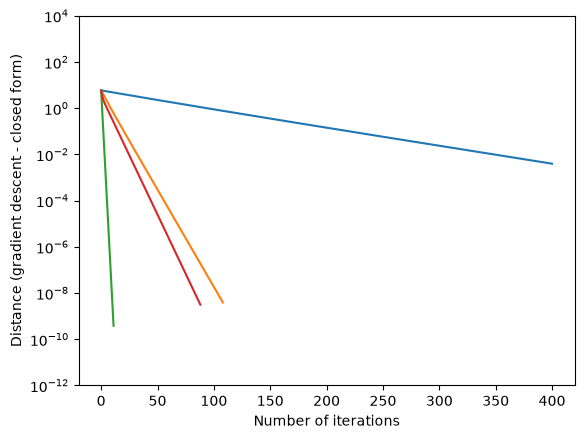

Answer: Adding a stopping criterion on whether the gradient is small enough. Sometimes, having only iterations as a stopping criterion will result in not converging to the optimal solution, as the gradient can still be large.


In [4]:
# Gradient descent parameters, learning rate gamma first
gamma = 0.1
# Then the maximum number of iterations, and a tolerance for the stopping criterion
num_iters = 400
tol = 1e-8

X_norm,y = exercise_data(degree=2)

#Getting the coeffiicents from exercise 3:
OLS_cf, Ridge_cf = reg_coefs(X_norm, y, 0.01)

def gd_OLS(X,y,gamma, num_iters, tol):
    # Initialize weights for gradient descent
    n_features = X.shape[1]
    theta_gdOLS = np.zeros(n_features)
    history = [theta_gdOLS.copy()]

    # Gradient descent loop
    for t in range(num_iters):
        # Compute gradients for OLS and Ridge    
        grad_OLS = (2.0 / n) * X.T @ (X @ theta_gdOLS - y)
    
        # Update parameters theta
        theta_gdOLS = theta_gdOLS - gamma * grad_OLS
    
        history.append(theta_gdOLS.copy())
        
        # Stopping criterion:  gradient is small enough
        if np.linalg.norm(grad_OLS) < tol:
            print(f"Converged after {t} iterations.")
            break
    if t == num_iters - 1:
            print("Reached maximum iterations without convergence.")

    return theta_gdOLS, t, history

    
def gd_Ridge(X,y,gamma, num_iters, tol):
    # Initialize weights for gradient descent
    n_features = X.shape[1]
    theta_gdRidge = np.zeros(n_features)
    history = [theta_gdRidge.copy()]

    # Gradient descent loop
    for t in range(num_iters):
        # Compute gradients for Ridge
        grad_Ridge = (2.0 / n) * X.T @ (X @ theta_gdRidge - y) + 2.0 * lam * theta_gdRidge

        # Update parameters theta
        theta_gdRidge = theta_gdRidge - gamma * grad_Ridge
    
        history.append(theta_gdRidge.copy())
        
        # Stopping criterion: If  gradient is small enough
        if np.linalg.norm(grad_Ridge) < tol:
            print(f"Converged after {t} iterations.")
            break
    if t == num_iters - 1:
            print("Reached maximum iterations without convergence.")

    return theta_gdRidge, t, history

    
n = len(y)


fig, ax = plt.subplots()
for gamma in [0.01, 0.1, 0.5, 0.8]:

    theta_gdOLS, t, history = gd_OLS(X_norm,y,gamma, num_iters, tol)
    
    # After the loop, theta contains the fitted coefficients
    print("Gradient Descent OLS coefficients:", theta_gdOLS)

    # print("Gradient Descent Ridge coefficients:", theta_gdRidge)
    dist = np.linalg.norm(history - OLS_cf, axis=1)

    ax.semilogy(dist)

ax.set_ylim(1e-12, 1e4)
ax.set_xlabel("Number of iterations")
ax.set_ylabel("Distance (gradient descent - closed form)")
plt.show()

print("Answer: Adding a stopping criterion on whether the gradient is small enough. Sometimes, having only iterations as a stopping criterion will result in not converging to the optimal solution, as the gradient can still be large.")


#Function from tuesday exercise:
def hessian_eigs(X, lam=0.0):
    """Eigenvalues of the Hessian (2/n) X^T X + 2 lambda I, Eqs. (4.14) and (4.17)."""
    n = len(X)
    return np.linalg.eigvalsh((2.0 / n) * X.T @ X + 2.0 * lam * np.eye(X.shape[1]))


### 4a)

Write first a gradient descent code for OLS only, using the above template.
Discuss the results as functions of the learning rate and the number of
iterations: for $\gamma \in \{0.01, 0.1, 0.5, 0.8\}$, how many iterations are
needed to reach the closed-form solution of exercise 3 to a given accuracy,
say $\|\boldsymbol{\theta}_k - \hat{\boldsymbol{\theta}}\|_2 < 10^{-6}$?
Plot this distance against the iteration number on a logarithmic scale.


### 4b)

Write then a similar code for Ridge regression. Add a stopping criterion
based on the number of iterations *and* on the size of the gradient (or on
the difference between the new and old $\boldsymbol{\theta}$). How would you
define a stopping criterion, and what goes wrong with a fixed number of
iterations alone?

### 4c) The learning rate and the eigenvalues of the Hessian

Compute the eigenvalues $\lambda_{\max}$ and $\lambda_{\min}$ of the Hessian
matrix of exercise 2 (use `np.linalg.eigvalsh`). Section 4.5 of the lecture
notes shows that gradient descent converges if and only if
$\gamma < 2/\lambda_{\max}$, Eq. (4.20), that the fastest convergence is
obtained for $\gamma^* = 2/(\lambda_{\max} + \lambda_{\min})$, and that the
number of iterations grows with the condition number
$\kappa = \lambda_{\max}/\lambda_{\min}$, Eq. (4.21). Verify the bound
numerically: run your code at $0.99 \cdot 2/\lambda_{\max}$ and at
$1.02 \cdot 2/\lambda_{\max}$.

Repeat for a design matrix with the columns $x, x^2, \dots, x^5$
(standardised). What happens to $\kappa$, to $\gamma_{\max}$ and to the number
of iterations, and why? Which of the two data sets does Ridge regression help
more, and in what sense?

### 4d) Checking the gradient with automatic differentiation

Project 1, part e), asks you to compute the gradient in two independent ways:
analytically, and by automatic differentiation. Write the OLS and Ridge cost
functions as ordinary Python functions of $\boldsymbol{\theta}$ using
`jax.numpy`, obtain their gradients with `jax.grad`, and compare with your
analytical gradients from exercise 2 at a random $\boldsymbol{\theta}$
(Section 4.14.7 of the lecture notes; remember
`jax.config.update("jax_enable_x64", True)`). Run your gradient descent code
with the automatic gradient and check that you obtain the same iterates.

In one or two sentences: why is automatic differentiation neither symbolic
nor numerical (finite-difference) differentiation, and what does a gradient
cost relative to one evaluation of the cost function (Section 4.14.4)?

degree 2: lambda_max = 5.1563, lambda_min = 2.1011, kappa = 2.5, gamma_max = 0.3879, gamma* = 0.2756
degree 5: lambda_max = 5.1563, lambda_min = 2.1011, kappa = 2.5, gamma_max = 0.3879, gamma* = 0.2756
Results for lambda = 0 :
Closed-form Ridge coefficients: [-1.0773505  5.854734 ]
Closed-form OLS coefficients: [-1.0773505  5.854734 ]
[-1.0773505  5.854734 ]
Reached maximum iterations without convergence.
Converged after 14 iterations.
Converged after 10 iterations.
Reached maximum iterations without convergence.
Reached maximum iterations without convergence.
Results for lambda = 0 :
Closed-form Ridge coefficients: [-1.23801293  5.85449694  0.17859203]
Closed-form OLS coefficients: [-1.23801293  5.85449694  0.17859203]
[-1.23801293  5.85449694  0.17859203]
Reached maximum iterations without convergence.
Converged after 316 iterations.
Converged after 178 iterations.
Converged after 912 iterations.
Reached maximum iterations without convergence.
Results for lambda = 0 :
Closed-form Rid

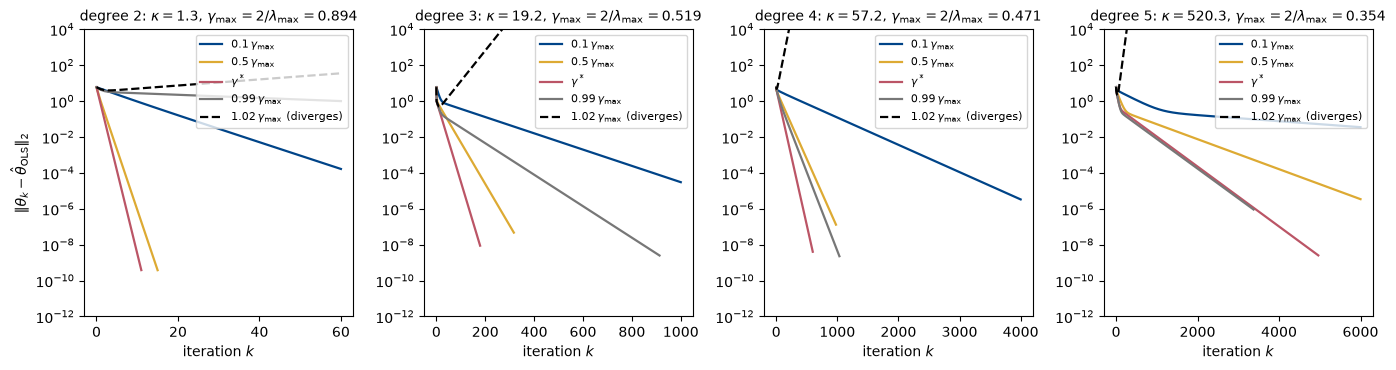

In [5]:
#Function from tuesday exercise:
def fig_gd_convergence(filename="week37_gd_convergence.pdf"):
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
    for ax, degree, iters in zip(axes, (2,3,4,5), (60, 1000,4000,6000)): #Looking at degree 2 to 5 for the design matrix
        X,y = exercise_data(degree=degree) #Standardising and fitting based on given degree
        OLS_cf,ridge_cf = reg_coefs(X, y,lam=0) #getting the OLS closed form
        print(OLS_cf)
        eigs = hessian_eigs(X)
        lmax, lmin = eigs.max(), eigs.min()
        gamma_star, gamma_max = 2.0 / (lmax + lmin), 2.0 / lmax
        gammas = [0.1 * gamma_max, 0.5 * gamma_max, gamma_star, 0.99 * gamma_max, 1.02 * gamma_max] #Running with different gammas
        labels = [r"$0.1\,\gamma_{\max}$", r"$0.5\,\gamma_{\max}$", r"$\gamma^*$",
                  r"$0.99\,\gamma_{\max}$", r"$1.02\,\gamma_{\max}$ (diverges)"]
        colors = [BLUE, YELLOW, RED, GREY, "black"]
        for gamma, lab, col in zip(gammas, labels, colors):
            
            theta_gdOLS, t, history = gd_OLS(X,y,gamma, num_iters=iters, tol=tol)

            dist = np.linalg.norm(np.asarray(history) - OLS_cf, axis=1)


            ax.semilogy(dist, color=col, label=lab, lw=1.6,
                        ls="--" if gamma > gamma_max else "-")
        ax.set_title(rf"degree {degree}: $\kappa={lmax/lmin:.1f}$, "
                     rf"$\gamma_{{\max}}=2/\lambda_{{\max}}={gamma_max:.3f}$", fontsize=10)
        ax.set_xlabel("iteration $k$")
        ax.set_ylim(1e-12, 1e4)
        ax.legend(fontsize=8, loc="upper right")

    axes[0].set_ylabel(r"$\|{\theta}_k-\hat{{\theta}}_{\mathrm{OLS}}\|_2$")
    fig.tight_layout()
    fig.savefig(filename, bbox_inches="tight")
    plt.close(fig)


for degree in (2, 5):
    eigs = hessian_eigs(X)
    print(f"degree {degree}: lambda_max = {eigs.max():.4f}, lambda_min = {eigs.min():.4f}, "
          f"kappa = {eigs.max()/eigs.min():.1f}, gamma_max = {2/eigs.max():.4f}, "
          f"gamma* = {2/(eigs.max()+eigs.min()):.4f}")
with np.errstate(all="ignore"):
    fig_gd_convergence("week37_gd_convergence.png")
from IPython.display import Image

Image("week37_gd_convergence.png")

Answer: When increasing the polynomial of the design matrix, Kappa (condition number) increases (so the ratio of gamma_max / gamma_min is greater), gamma_max becomes greater and we need a larger number of iterations before it converges.

In [6]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax import grad

def cost_OLS(theta, X, y):
    return jnp.sum((X @ theta - y)**2) / len(y)

def cost_Ridge(theta, X, y, lam):
    return jnp.sum((X @ theta - y)**2) / len(y) + lam * jnp.sum(theta**2)


theta_test = rng.standard_normal(n_features)
grad_OLS_ad = grad(cost_OLS)(theta_test, jnp.asarray(X_norm), jnp.asarray(y_centered))
grad_OLS_analytical = - (2.0 / n) * X_norm.T @ (y_centered - X_norm @ theta_test)
print("max |AD - analytical| =", np.max(np.abs(np.asarray(grad_OLS_ad) - grad_OLS_analytical)))

print("Answer: ...")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


max |AD - analytical| = 3.552713678800501e-15
Answer: ...


## Exercise 5: Ridge regression and a new synthetic data set

We create a synthetic linear regression data set with a sparse underlying
relationship: many features, of which only a few contribute to the target. We
use 10 features with only 3 non-zero weights in the true model, so that the
target is a linear combination of a few features (with known coefficients)
plus random noise. The steps are:

* decide on the number of samples and features (100 samples, 10 features);
* define the *true* coefficient vector with mostly zeros, for example
  $\boldsymbol{\theta}_{\mathrm{true}} = [5.0, -3.0, 0, 0, 0, 0, 2.0, 0, 0, 0]$,
  meaning only features 0, 1 and 6 have a real effect on $y$;
* sample the feature matrix $\boldsymbol{X}$ from a standard normal
  distribution, so that the features are roughly centred around 0;
* compute $\boldsymbol{y} = \boldsymbol{X}\boldsymbol{\theta}_{\mathrm{true}} + \boldsymbol{\varepsilon}$
  with Gaussian noise $\boldsymbol{\varepsilon}$.

In [9]:
import numpy as np

# Set random seed for reproducibility
np.random.seed(0)

# Define dataset size
n_samples = 100
n_features = 10

# Define true coefficients (sparse linear relationship)
theta_true = np.array([5.0, -3.0, 0.0, 0.0, 0.0, 0.0, 2.0, 0.0, 0.0, 0.0])

# Generate feature matrix X (n_samples x n_features) with random values
X = np.random.randn(n_samples, n_features)  # standard normal distribution

# Generate target values y with a linear combination of X and theta_true, plus noise
noise = 0.5 * np.random.randn(n_samples)    # Gaussian noise
y = X @ theta_true + noise


# Standardize features (zero mean, unit variance for each feature)
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_std[X_std == 0] = 1  # safeguard to avoid division by zero for constant features
X_norm = (X - X_mean) / X_std

# Center the target to zero mean (optional, to simplify intercept handling)
y_mean = y.mean()
y_centered = y - y_mean

#Analytical experssions:
theta_OLS, theta_ridge = reg_coefs(X_norm, y_centered, 0.1)

#Gradient descent
theta_gdOLS, t, history = gd_OLS(X_norm,y_centered,gamma=0.1, num_iters=1000, tol=1e-6)
theta_gdridge, t, history = gd_Ridge(X_norm,y_centered,gamma=0.1, num_iters=1000, tol=1e-6)

print("OLS GD",theta_gdOLS)
print("Ridge GD",theta_gdridge)

print("Answer: OLS seems to give better results than Ridge as the coefficients are more similar to the true values in OLS. The gradient descent method seems to give the best results. The Ridge penalises the coefficients, and as we have a lot of 0s and only features 0,1,6 have effect on y, this is not optimal.")

#Computing the Hessian and its condition number Kappa

eigs = hessian_eigs(X)
lmax, lmin = eigs.max(), eigs.min()
kappa = lmax/lmin
print("condition number:", kappa)
print("Answer: the condition number is much lower here than for the degree 5 in exercise 4c, meaning the gradient descent converges much more easily. This is because the Hessian works best when the features are not correlated to each other, which applies more in this case than in 4c.")

Results for lambda = 0.1 :
Closed-form Ridge coefficients: [ 4.55939394 -2.57368578 -0.01541807  0.18880688 -0.14678708 -0.1008156
  1.62042026  0.02538038 -0.04540125 -0.04206634]
Closed-form OLS coefficients: [ 5.03241281e+00 -2.89258175e+00 -1.55189951e-02  1.51795012e-01
 -6.83299260e-02 -4.40147965e-02  1.76999871e+00  4.37643569e-03
  4.52550260e-02 -4.97610000e-02]
Converged after 113 iterations.
Converged after 113 iterations.
OLS GD [ 5.03241262e+00 -2.89258141e+00 -1.55189816e-02  1.51795214e-01
 -6.83302623e-02 -4.40149918e-02  1.76999866e+00  4.37639542e-03
  4.52547996e-02 -4.97609653e-02]
Ridge GD [ 5.03241262e+00 -2.89258141e+00 -1.55189816e-02  1.51795214e-01
 -6.83302623e-02 -4.40149918e-02  1.76999866e+00  4.37639542e-03
  4.52547996e-02 -4.97609653e-02]
Answer: OLS seems to give better results than Ridge as the coefficients are more similar to the true values in OLS. The gradient descent method seems to give the best results. The Ridge penalises the coefficients, and

This code produces a data set where only features 0, 1 and 6 significantly
influence $\boldsymbol{y}$; the rest have zero true coefficient. Feature 0 has
a true weight of $5.0$, feature 1 of $-3.0$ and feature 6 of $2.0$, so the
expected relationship is

$$
y \approx 5x_0 - 3x_1 + 2x_6 + \text{noise}.
$$

You can remove the noise if you wish.

Fit the above data set using OLS and Ridge regression with the analytical
expressions and with your own gradient descent code (scale the data as in
exercise 1). If everything works, the learned coefficients should be close to
the true values $[5.0, -3.0, 0, \dots, 2.0, \dots]$. Due to regularisation
and noise the learned values will not exactly equal the true ones, but they
should be in the same ballpark. Which method, OLS or Ridge, gives the best
results — and best in which sense? Compute the condition number of the
Hessian for this data set: why does gradient descent converge so much more
easily here than for the degree-5 polynomial of exercise 4c)?

## Exercise 6: adding momentum

Part f) of Project 1 asks you to extend your gradient descent code with
momentum and, next week, with the adaptive methods AdaGrad, RMSProp and Adam.
Start here with momentum, Eq. (4.23) of the lecture notes,

$$
\boldsymbol{v}_{k+1} = \beta\boldsymbol{v}_k + \gamma\nabla_{\boldsymbol{\theta}} C(\boldsymbol{\theta}_k),
\qquad
\boldsymbol{\theta}_{k+1} = \boldsymbol{\theta}_k - \boldsymbol{v}_{k+1},
$$

which is one line more than the code of exercise 4. Use the degree-5
polynomial data of exercise 4c), where plain gradient descent is slow, and
the learning rate $\gamma = 0.9 \cdot 2/\lambda_{\max}$.

1. Run $\beta \in \{0, 0.5, 0.9\}$ and count the iterations needed to reach
   $\|\boldsymbol{\theta}_k - \hat{\boldsymbol{\theta}}\|_2 < 10^{-6}$. Plot
   the three convergence curves on a logarithmic scale.
2. Section 4.6 shows that, with optimally tuned parameters, momentum reduces
   the iteration count from $\propto\kappa$ to $\propto\sqrt\kappa$,
   Eq. (4.26). How large a reduction do you observe with the fixed $\gamma$
   above, and how does it compare with $\sqrt\kappa$? Try the optimal
   momentum $\beta^* = \big((\sqrt\kappa-1)/(\sqrt\kappa+1)\big)^2$.
3. Explain, in terms of Eqs. (4.24) and (4.25), why momentum speeds up the
   flat directions and damps the oscillations in the steep ones.
4. (Optional) Repeat with $\gamma = 1.5 \cdot 2/\lambda_{\max}$, where plain
   gradient descent diverges. What happens with momentum, and why?

Degree 5: lambda_max = 5.653, lambda_min = 1.09e-02, kappa = 520
Results for lambda = 0 :
Closed-form Ridge coefficients: [-1.21073258  5.94420384  0.10307577 -0.0912351   0.04790703]
Closed-form OLS coefficients: [-1.21073258  5.94420384  0.10307577 -0.0912351   0.04790703]
   beta = 0.0: first iteration with |theta - closed form| < 1e-6: 3689
   beta = 0.5: first iteration with |theta - closed form| < 1e-6: 1829
   beta = 0.9: first iteration with |theta - closed form| < 1e-6: 284
   beta = 0.8395811881098885: first iteration with |theta - closed form| < 1e-6: 514
Results for lambda = 0 :
Closed-form Ridge coefficients: [-1.21073258  5.94420384  0.10307577 -0.0912351   0.04790703]
Closed-form OLS coefficients: [-1.21073258  5.94420384  0.10307577 -0.0912351   0.04790703]


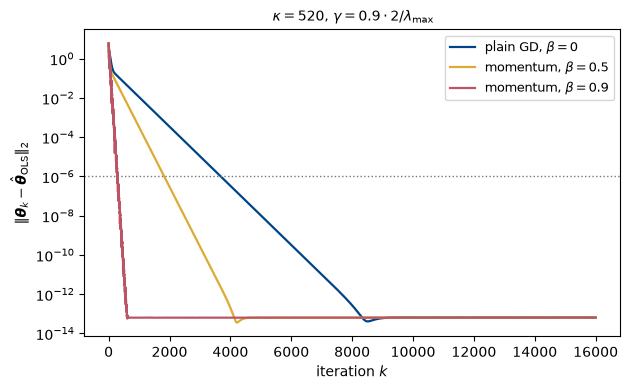

In [ ]:
# Your momentum code here

lam = 0
""" Functions from tuesday exercise, adjusted to match"""
def momentum_descent(X, y, gamma, beta, lam=0.0, num_iters=5000, tol=1e-8):
    """Gradient descent with momentum, Eq. (4.23). beta = 0 is plain gradient descent."""
    theta, v = np.zeros(X.shape[1]), np.zeros(X.shape[1])
    history = [theta.copy()]
    n = len(y)
    for t in range(num_iters):
        gradient = (2.0 / n) * X.T @ (X @ theta - y) + 2.0 * lam * theta

        v = beta * v + gamma * gradient
        theta = theta - v

        history.append(theta.copy())
                
        # Stopping criterion:  gradient is small enough
        if np.linalg.norm(gradient) < tol:
            print(f"Converged after {t} iterations.")
            break
    
    return np.array(history), t + 1


def fig_momentum(filename="week37_momentum.pdf"):
    X_norm, y_centered = exercise_data(degree=5)

    OLS_cf,ridge_cf = reg_coefs(X_norm, y_centered,lam=lam) #getting the OLS closed form
    eigs = hessian_eigs(X_norm)
    lmax, lmin = eigs.max(), eigs.min()
    gamma = 0.9 * 2.0 / lmax
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    for beta, col, lab in ((0.0, BLUE, r"plain GD, $\beta=0$"),
                            (0.5, YELLOW, r"momentum, $\beta=0.5$"),
                            (0.9, RED, r"momentum, $\beta=0.9$")):
        hist, _ = momentum_descent(X_norm, y_centered, gamma, beta, num_iters=16000, tol=0.0)
        ax.semilogy(np.linalg.norm(hist - ridge_cf, axis=1), color=col, lw=1.6, label=lab)
    ax.axhline(1e-6, color=GREY, ls=":", lw=1)
    ax.set_xlabel("iteration $k$")
    ax.set_ylabel(r"$\|\boldsymbol{\theta}_k-\hat{\boldsymbol{\theta}}_{\mathrm{OLS}}\|_2$")
    ax.set_title(rf" $\kappa={lmax/lmin:.0f}$, "
                 rf"$\gamma=0.9\cdot2/\lambda_{{\max}}$", fontsize=10)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(filename, bbox_inches="tight")
    plt.close(fig)


X_norm, y_centered = exercise_data(degree=5)

newbeta = ((np.sqrt(524)-1)/(np.sqrt(524)+1))**2 #New beta based on the equation given

eigs = hessian_eigs(X_norm)
lmax, lmin = eigs.max(), eigs.min()
print(f"Degree 5: lambda_max = {lmax:.3f}, lambda_min = {lmin:.2e}, kappa = {lmax/lmin:.0f}")
gamma = 0.9 * 2.0 / lmax
OLS_cf,ridge_cf = reg_coefs(X_norm, y_centered,lam=lam) #getting the OLS closed form

for beta in (0.0, 0.5, 0.9,newbeta):
    hist, _ = momentum_descent(X_norm, y_centered, gamma, beta, num_iters=20000, tol=0.0)
    dist = np.linalg.norm(hist - ridge_cf, axis=1)
    first = np.argmax(dist < 1e-6) if np.any(dist < 1e-6) else None
    print(f"   beta = {beta}: first iteration with |theta - closed form| < 1e-6: {first}")
fig_momentum("week37_momentum.png")
Image("week37_momentum.png")

print("Answer: In terms of Eqs 4.24 and 4.25, the momentum speeds up the flat direction and damps the oscillations in the steep ones, because ...")

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 1; the
right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| My loop stopped after its allowed iterations with a small but nonzero gradient. Has it converged? | No. Along the slowest direction the error contracts by $\lvert 1-\gamma\lambda_{\min}\rvert$ per step, Eq. (4.19), and can still be $\|\nabla C\|/\lambda_{\min}$ large. Stop on the gradient (or on $\Delta\boldsymbol{\theta}$), never on a count alone. |
| Why does gradient descent care about the scaling of the columns when the closed form does not? | The closed form solves the normal equations in one go; gradient descent takes the same step in every direction, and the column scales set the eigenvalue spread $\kappa(\boldsymbol{H}) = \kappa_2(\boldsymbol{X})^2$, Eq. (4.22), hence the iteration count. Same minimum, different road. |
| Ridge converged in far fewer iterations than OLS. Did it find a better OLS solution? | No — it found the exact solution of a *different* problem, Eq. (4.16). The penalty lifts $\lambda_{\min}$, Eq. (4.17), which shortens the road, but the destination moved: bias traded for variance. |
| The same code diverged at $\gamma = 0.5$ on one data set and converged at $\gamma = 0.8$ on another. Why? | Stability requires $\gamma < 2/\lambda_{\max}$, Eq. (4.20), and $\lambda_{\max}$ is a property of $\boldsymbol{X}$, not of the algorithm. Compute it — `np.linalg.eigvalsh(2/n * X.T @ X).max()` — before you choose $\gamma$. |
| The closed form and my converged gradient descent disagree in the second decimal for Ridge. Which is wrong? | Possibly neither: with the cost $\frac{1}{n}\|\boldsymbol{X}\boldsymbol{\theta}-\boldsymbol{y}\|^2 + \lambda\|\boldsymbol{\theta}\|^2$ the closed form has $n\lambda\boldsymbol{I}$, Eq. (3.95), and `scikit-learn`'s `alpha` is $n\lambda$. Compare cost functions before comparing methods. |
| My JAX gradient agrees with my analytical gradient to $10^{-15}$. What have I proved? | That your derivation matches the cost you *wrote down* — an algebra error would show as $10^{-2}$. Not that the cost is the one you meant (a missing $1/n$, a penalised intercept): both gradients would then agree and both would be wrong. |
| Momentum converged where plain gradient descent diverged. Is the learning rate now unimportant? | No. The stability edge moves to $2(1+\beta)/\lambda_{\max}$, and the best $\beta$ is tied to $\kappa$ through Eq. (4.26); too much momentum rings for ever. Two data-dependent knobs instead of one. |
| Why does momentum help, in one sentence? | It adds up gradients that keep pointing the same way (the flat directions, effective step $\gamma/(1-\beta)$, Eq. (4.25)) and cancels gradients that alternate in sign (the steep direction), so the iteration count scales with $\sqrt\kappa$ instead of $\kappa$. |
| I swap the OLS cost for a neural-network cost and keep `jax.grad`. What changes? | In the code: only the definition of the cost. In the theory: convexity is gone, so a stationary point need not be the global minimum (Section 4.1) and the bound of Eq. (4.20) is only local — good behaviour becomes empirical, not a theorem. |
| Why reverse mode for training, and what is its price? | One scalar output and $p$ inputs: reverse mode returns the full gradient for two or three cost evaluations, whatever $p$ (the cheap gradient principle, Section 4.14.4); forward mode or finite differences would need $p$ sweeps. The price is the tape — every intermediate value is stored until the backward sweep has used it: memory, not time. |
| Why not just use finite differences to check the gradient, and be done with it? | For a *quadratic* cost the central difference is exact up to rounding, so it would pass; for anything else its best accuracy is about $10^{-11}$ at $h\approx10^{-6}$, Eq. (4.46), and it costs $2p$ evaluations. Use it as a check at $h \approx 10^{-5}$, not as the gradient. |

### Practicalities

Deliver your solutions (a single Jupyter notebook, with the analytical parts
either typeset in Markdown/LaTeX or as a scanned handwritten note) in Canvas
before **Friday September 11 at midnight**. Collaboration is encouraged — list
your collaborators.